# 01 — p5986 raw LabVIEW mechanical binary → dataframe/HDF5

This notebook only parses `mechData/p5986`. It does not calibrate or clean the data.

p5986 reference facts checked against the original preprocessing notebook:

- 5,673,000 mechanical records;
- channels: `Time`, `Vert DCDT`, `Vert LOAD`, `Hor DCDT`, `Hor LOAD`, `VOB DCDT`, `sync`;
- the footer is 336 bytes and the data body is little-endian int32 records.


In [ ]:
# ===== Common setup: Google Drive path and output folder =====
from pathlib import Path
import os, json, re, math, glob, shutil, warnings
import numpy as np
import pandas as pd

try:
    from google.colab import drive
    drive.mount('/content/drive')
except Exception as exc:
    print('Not running in Colab or Drive already mounted:', exc)

# Edit only when the Drive shortcut/folder is elsewhere.
P5986_ROOT = Path(os.environ.get(
    'P5986_ROOT',
    '/content/drive/MyDrive/MLStressDrop/p5986',
))
assert P5986_ROOT.exists(), (
    f'Cannot find p5986 folder: {P5986_ROOT}. '
    'Add a Drive shortcut or edit P5986_ROOT.'
)

MECH_DIR = P5986_ROOT / 'mechData'
AC_DIR = P5986_ROOT / 'acData'
RUN1_DIR = AC_DIR / 'run1'
MAT_DIR = AC_DIR / 'MatFiles'
OUT_DIR = P5986_ROOT / 'colab_outputs_p5986'
OUT_DIR.mkdir(exist_ok=True, parents=True)
print('P5986_ROOT =', P5986_ROOT)
print('OUT_DIR    =', OUT_DIR)


Mounted at /content/drive
P5986_ROOT = /content/drive/MyDrive/MLStressDrop/p5986
OUT_DIR    = /content/drive/MyDrive/MLStressDrop/p5986/colab_outputs_p5986


In [ ]:
# ===== Small HDF5 utilities =====
import h5py

def _as_array(x):
    x = np.asarray(x)
    if x.dtype == object:
        x = x.astype(str)
    return x

def save_dict_h5(path, data, attrs=None):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    with h5py.File(path, 'w') as f:
        for k, v in data.items():
            arr = _as_array(v)
            if arr.dtype.kind in {'U', 'O'}:
                dt = h5py.string_dtype(encoding='utf-8')
                f.create_dataset(k, data=arr.astype(str), dtype=dt)
            else:
                f.create_dataset(k, data=arr, compression='gzip', compression_opts=4, shuffle=True)
        if attrs:
            for k, v in attrs.items():
                f.attrs[k] = json.dumps(v) if isinstance(v, (dict, list, tuple)) else v
    print('saved:', path)

def load_h5_to_dict(path):
    out = {}
    with h5py.File(path, 'r') as f:
        for k in f.keys():
            out[k] = f[k][()]
            if getattr(out[k], 'dtype', None) is not None and out[k].dtype.kind == 'S':
                out[k] = out[k].astype(str)
    return out

def load_h5_to_df(path):
    d = load_h5_to_dict(path)
    return pd.DataFrame({k: np.ravel(v) for k, v in d.items() if np.asarray(v).ndim <= 1})


## 1. Inventory and experiment-specific invariants

p5986 uses its own raw binary, settings, sync file, and fully passive acoustic run.


In [ ]:
# use dictionary to assign file routes

expected = {
    'raw mechanical binary': MECH_DIR / 'p5986',
    'original converted hdf5': MECH_DIR / 'p5986l.hdf5',
    'original cleaned hdf5': MECH_DIR / 'p5986ll.hdf5',
    'acoustic settings': MAT_DIR / 'p5986_run1.mat',
    'acoustic sync': AC_DIR / 'p5986_sync_run1.mat',
    'acoustic run folder': RUN1_DIR,
    'runsheet': P5986_ROOT / 'p5986_runsheet.pdf',
}
for label, path in expected.items():
    print(f'{label:28s}: {path}  exists={path.exists()}')

def wf_number(path):
    match = re.fullmatch(r'WF_(\d+)\.ac', path.name)
    if match is None:
        raise ValueError(f'Unexpected waveform filename: {path.name}')
    return int(match.group(1))

wf_files = sorted(RUN1_DIR.glob('WF_*.ac'), key=wf_number) if RUN1_DIR.exists() else []
wf_numbers = np.array([wf_number(path) for path in wf_files], dtype=int)
print('WF file count:', len(wf_files))
if len(wf_files):
    print('numeric range:', (int(wf_numbers.min()), int(wf_numbers.max())))
    expected_numbers = set(range(int(wf_numbers.min()), int(wf_numbers.max()) + 1))
    missing_numbers = sorted(expected_numbers.difference(wf_numbers.tolist()))
    print('missing WF numbers:', missing_numbers[:20], 'count =', len(missing_numbers))
    print('first/last:', wf_files[0].name, wf_files[-1].name)


raw mechanical binary       : /content/drive/MyDrive/MLStressDrop/p5986/mechData/p5986  exists=True
original converted hdf5     : /content/drive/MyDrive/MLStressDrop/p5986/mechData/p5986l.hdf5  exists=True
original cleaned hdf5       : /content/drive/MyDrive/MLStressDrop/p5986/mechData/p5986ll.hdf5  exists=True
acoustic settings           : /content/drive/MyDrive/MLStressDrop/p5986/acData/MatFiles/p5986_run1.mat  exists=True
acoustic sync               : /content/drive/MyDrive/MLStressDrop/p5986/acData/p5986_sync_run1.mat  exists=True
acoustic run folder         : /content/drive/MyDrive/MLStressDrop/p5986/acData/run1  exists=True
runsheet                    : /content/drive/MyDrive/MLStressDrop/p5986/p5986_runsheet.pdf  exists=True
WF file count: 2922
numeric range: (1, 2922)
missing WF numbers: [] count = 0
first/last: WF_1.ac WF_2922.ac


## 2. Raw LabVIEW binary reader

The parser follows the original `lv2py.py` layout. Channel name `sync` is normalized to `Sync` only at the dataframe boundary so downstream notebooks have one stable column name.


In [ ]:
import struct

FOOTER_BYTES = 336

def read_labview_binary_to_dataframe(filename):
    filename = Path(filename)
    assert filename.exists(), f'Missing raw mechanical binary: {filename}'
    filesize = filename.stat().st_size
    with open(filename, 'rb') as stream:
        data_bytes = stream.read(filesize - FOOTER_BYTES)
        footer_raw = stream.read(FOOTER_BYTES)
    footer = footer_raw.decode('utf-8', errors='replace')

    exp_name = footer[0:32].split(' ', 1)[0]
    footer_channels = footer[48:64].count('l')
    channel_names = ['Time']
    for index in range(1, footer_channels + 1):
        start = 80 + 16 * (index - 1)
        channel_names.append(footer[start:start + 15].split('  ', 1)[0].strip())

    values = np.frombuffer(data_bytes, dtype='<i4')
    n_columns = len(channel_names)
    if values.size % n_columns:
        raise ValueError(
            f'Data body has {values.size} int32 values, not divisible by {n_columns} channels.'
        )
    frame = pd.DataFrame(values.reshape(-1, n_columns), columns=channel_names)
    if 'sync' in frame.columns and 'Sync' not in frame.columns:
        frame = frame.rename(columns={'sync': 'Sync'})

    print('experiment:', exp_name)
    print('file size:', filesize)
    print('columns:', frame.columns.tolist())
    print('records:', len(frame))
    return frame, footer

raw_path = MECH_DIR / 'p5986'
raw_df, footer = read_labview_binary_to_dataframe(raw_path)
assert len(raw_df) == 5_673_000, 'Unexpected p5986 record count.'
assert raw_df.columns.tolist() == [
    'Time', 'Vert DCDT', 'Vert LOAD', 'Hor DCDT',
    'Hor LOAD', 'VOB DCDT', 'Sync',
]
raw_df.head()


experiment: p5986
file size: 158844336
columns: ['Time', 'Vert DCDT', 'Vert LOAD', 'Hor DCDT', 'Hor LOAD', 'VOB DCDT', 'Sync']
records: 5673000


,Time,Vert DCDT,Vert LOAD,Hor DCDT,Hor LOAD,VOB DCDT,Sync
0,10000,-8531760,-312579,-1396451,-375188,-9158700,2763755
1,10000,-8531806,-312553,-1396281,-375162,-9158700,2763761
2,10000,-8531692,-312525,-1395717,-375212,-9158700,2763771
3,10000,-8531993,-312600,-1395435,-375245,-9158700,2763769
4,10000,-8531824,-312738,-1395302,-375359,-9158700,2763772


In [ ]:
# Check
FOOTER_BYTES = 336

with open(raw_path, 'rb') as f:
    raw = f.read()

data_bytes = raw[:-FOOTER_BYTES]
footer_raw = raw[-FOOTER_BYTES:]

footer = footer_raw.decode('utf-8', errors='replace')

print("Footer length:", len(footer_raw))
print("footer[0:32]  =", repr(footer[0:32]))
print("footer[48:64] =", repr(footer[48:64]))

print("\nChannel name slots:")
for i in range(16):
    start = 80 + 16*i
    end = start + 16
    print(i+1, start, end, repr(footer[start:end]))


Footer length: 336
footer[0:32]  = 'p5986                           '
footer[48:64] = 'lllllluuuuuuuuuu'

Channel name slots:
1 80 96 'Vert DCDT       '
2 96 112 'Vert LOAD       '
3 112 128 'Hor DCDT        '
4 128 144 'Hor LOAD        '
5 144 160 'VOB DCDT        '
6 160 176 'sync            '
7 176 192 'Ppa Disp        '
8 192 208 'Ppa LOAD        '
9 208 224 'Unused          '
10 224 240 'Unused          '
11 240 256 'Unused          '
12 256 272 'Unused          '
13 272 288 'Unused          '
14 288 304 'Unused          '
15 304 320 'Unused          '
16 320 336 'Unused          '


In [ ]:
# Check the output table
# 1. binary shape
filesize = raw_path.stat().st_size
data_bytes_n = filesize - 336
ncols = len(raw_df.columns)

print("data bytes:", data_bytes_n)
print("int32 values:", data_bytes_n // 4)
print("data_bytes_n % 4:", data_bytes_n % 4)
print("(data_bytes_n // 4) % ncols:", (data_bytes_n // 4) % ncols)
print("expected filesize:", len(raw_df) * ncols * 4 + 336)

# 2. Time column
print("\nTime checks:")
print("nunique:", raw_df['Time'].nunique())
print(raw_df['Time'].head(20).to_list())
print(raw_df['Time'].tail(20).to_list())
print(raw_df['Time'].diff().describe())
print(raw_df['Time'].value_counts().head())

# 3. basic statistics
print("\nRaw data statistics:")
display(raw_df.describe().T)


data bytes: 158844000
int32 values: 39711000
data_bytes_n % 4: 0
(data_bytes_n // 4) % ncols: 0
expected filesize: 158844336

Time checks:
nunique: 4
[10000, 10000, 10000, 10000, 10000, 10000, 10000, 10000, 10000, 10000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000]
[10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10]
count    5.672999e+06
mean    -1.760973e-03
std      3.797680e+00
min     -9.000000e+03
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      0.000000e+00
Name: Time, dtype: float64
Time
10       5672000
100          900
1000          90
10000         10
Name: count, dtype: int64

Raw data statistics:


,count,mean,std,min,25%,50%,75%,max
Time,5673000.0,1.004759e+01,1.388355e+01,10.0,10.00,10.0,10.00,10000.0
Vert DCDT,5673000.0,2.436662e+06,4.836235e+06,-8535230.0,902973.00,4143943.0,6340272.50,6746008.0
Vert LOAD,5673000.0,4.594983e+05,6.138251e+05,-317286.0,-313131.00,937126.0,989440.00,1093922.0
Hor DCDT,5673000.0,2.831927e+06,2.116030e+06,-1456440.0,3750109.75,3914544.0,3933443.00,3948728.0
Hor LOAD,5673000.0,2.636466e+05,3.276965e+05,-381502.0,428417.00,432485.0,432997.00,738671.0
VOB DCDT,5673000.0,-2.130739e+06,5.733218e+06,-9158700.0,-6807715.00,-3825675.5,3514673.75,8536085.0
Sync,5673000.0,2.764143e+06,2.236017e+02,2760329.0,2764032.00,2764176.0,2764323.00,2764886.0


In [ ]:
RAW_H5 = OUT_DIR / '01_mech_raw_p5986_from_binary.h5'
META_JSON = OUT_DIR / '01_mech_raw_p5986_metadata.json'
save_dict_h5(RAW_H5, {c: raw_df[c].to_numpy() for c in raw_df.columns}, attrs={'source': str(raw_path), 'columns': list(raw_df.columns)})
META_JSON.write_text(json.dumps({'source': str(raw_path), 'columns': list(raw_df.columns), 'n_records': len(raw_df), 'footer': footer}, indent=2))
print('saved metadata:', META_JSON)


saved: /content/drive/MyDrive/MLStressDrop/p5986/colab_outputs_p5986/01_mech_raw_p5986_from_binary.h5
saved metadata: /content/drive/MyDrive/MLStressDrop/p5986/colab_outputs_p5986/01_mech_raw_p5986_metadata.json


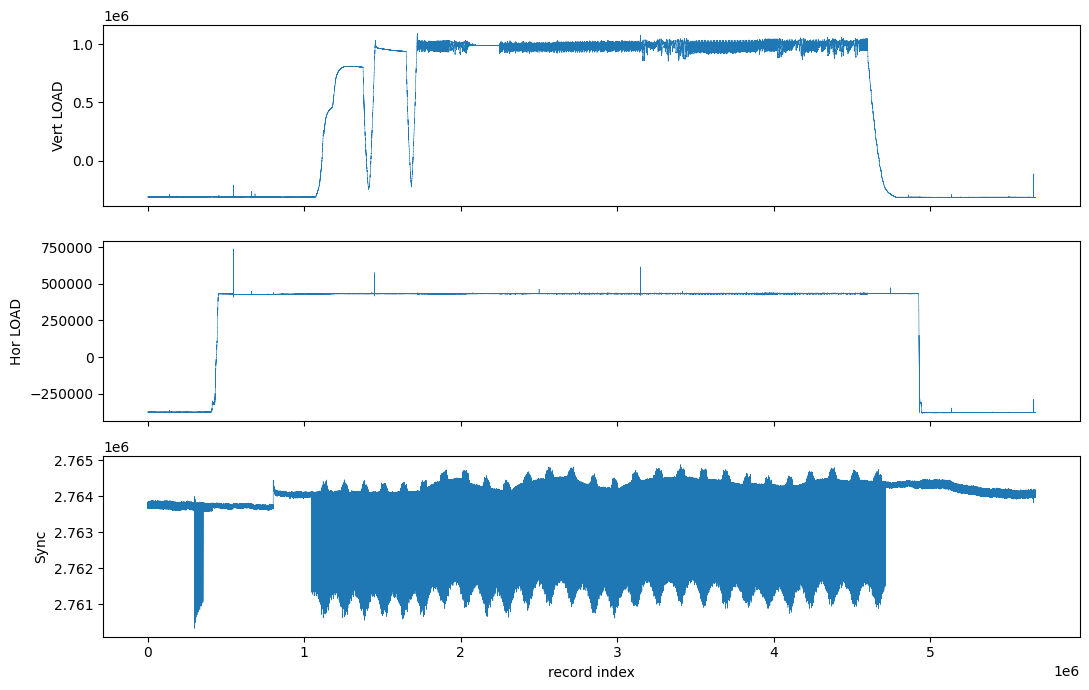

In [ ]:
# Quick sanity plots
import matplotlib.pyplot as plt
fig, ax = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
for a, col in zip(ax, ['Vert LOAD', 'Hor LOAD', 'Sync']):
    if col in raw_df:
        a.plot(raw_df[col].to_numpy(), lw=0.4)
        a.set_ylabel(col)
ax[-1].set_xlabel('record index')
plt.tight_layout()
